# Vẽ ma trận nhầm lẫn cho ví dụ xét nghiệm sàng lọc bệnh

Giả sử 1000 người đi xét nghiệm, trong đó 100 người thực sự mắc bệnh. Quy ước giống scikit-learn: hàng là nhãn thật, cột là nhãn dự đoán, lớp 0 đứng trước.

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

IMAGES = Path('.')   # thư mục images/ (notebook chạy trong images/)

Số liệu giả định: ma trận nhầm lẫn $[[TN, FP], [FN, TP]]$ và ý nghĩa từng ô.

In [2]:
matrix = np.array([[855, 45],    # thật không bệnh: TN, FP
                   [10, 90]])    # thật mắc bệnh:   FN, TP
cells = {
    (0, 0): ('TN', 'Người khỏe,\nkết quả âm tính', True),
    (0, 1): ('FP', 'Người khỏe bị\nbáo nhầm là mắc bệnh', False),
    (1, 0): ('FN', 'Người bệnh\nbị bỏ sót', False),
    (1, 1): ('TP', 'Người bệnh\nđược phát hiện', True),
}
style = {   # màu nền và màu viền: đúng (đường chéo chính) và sai (ngoài đường chéo)
    True: dict(face='#DCEFD9', edge='#2E7D32', tag='✓ Đúng'),
    False: dict(face='#FBDCDA', edge='#C62828', tag='✗ Sai'),
}
print('Tổng số người:', matrix.sum())
print('Số người theo nhãn thật (không bệnh, mắc bệnh):', matrix.sum(axis=1))

Tổng số người: 1000
Số người theo nhãn thật (không bệnh, mắc bệnh): [900 100]


Vẽ hình và lưu ảnh. Ô (hàng $i$, cột $j$) đặt tại $x = j$, $y = 1 - i$ để hàng 0 nằm trên; bên phải mỗi hàng ghi tổng số người thật thuộc lớp đó.

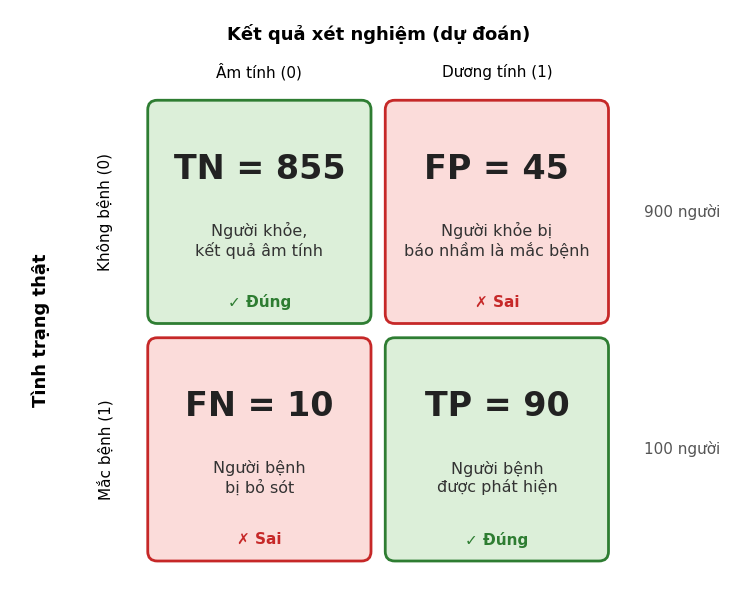

In [3]:
fig, ax = plt.subplots(figsize=(8.5, 6))
gap = 0.03   # khoảng trống giữa các ô
for (row, col), (code, meaning, correct) in cells.items():
    s = style[correct]
    x, y = col, 1 - row
    ax.add_patch(FancyBboxPatch((x + gap, y + gap), 1 - 2 * gap, 1 - 2 * gap,
                                boxstyle='round,pad=0,rounding_size=0.04',
                                facecolor=s['face'], edgecolor=s['edge'], lw=2))
    ax.text(x + 0.5, y + 0.68, '%s = %d' % (code, matrix[row, col]), ha='center', va='center',
            fontsize=24, fontweight='bold', color='#222222')
    ax.text(x + 0.5, y + 0.38, meaning, ha='center', va='center', fontsize=11.5, color='#333333')
    ax.text(x + 0.5, y + 0.12, s['tag'], ha='center', va='center', fontsize=11, fontweight='bold', color=s['edge'])

# Nhãn cột (dự đoán) phía trên, nhãn hàng (thật) bên trái
ax.text(1, 2.25, 'Kết quả xét nghiệm (dự đoán)', ha='center', va='center', fontsize=13, fontweight='bold')
for col, label in enumerate(['Âm tính (0)', 'Dương tính (1)']):
    ax.text(col + 0.5, 2.09, label, ha='center', va='center', fontsize=11)
ax.text(-0.42, 1, 'Tình trạng thật', ha='center', va='center', fontsize=13, fontweight='bold', rotation=90)
for row, label in enumerate(['Không bệnh (0)', 'Mắc bệnh (1)']):
    ax.text(-0.15, 1.5 - row, label, ha='center', va='center', fontsize=11, rotation=90)

# Tổng theo hàng: số người thật không bệnh / mắc bệnh
for row, total in enumerate(matrix.sum(axis=1)):
    ax.text(2.12, 1.5 - row, '%d người' % total, ha='left', va='center', fontsize=11, color='#555555')

ax.set_xlim(-0.55, 2.55); ax.set_ylim(-0.05, 2.35)
ax.set_aspect('equal'); ax.axis('off')
fig.tight_layout()
fig.savefig(IMAGES / 'confusion_matrix_screening.png', dpi=150, bbox_inches='tight')